# Deep Learning HW3

Erfan Ahmadi, Mohammad Ali Olama

# Q1

## Part 1.1

### Data Loading and Prepration

Install yfinance

In [1]:
#ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Install yfinance
!pip install yfinance

In [3]:
# import yfinance as yf
# import pandas as pd
# from datetime import date

# # Define the ticker symbol and date range
# ticker = "CL=F"
# start_date = "2010-01-01"
# # Today should be the end date
# end_date = date.today().strftime('%Y-%m-%d')

# # Download the data
# data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=False)

As the above cell does not downloaded properly we use the data shared in the group

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Convert the Data into the Pandas Format

In [5]:

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/TEIAS/Deep/HW3/CA3/raw_oil_data.csv')
df.head()


,Price,Adj Close,Close,High,Low,Open,Volume
0,Ticker,CL=F,CL=F,CL=F,CL=F,CL=F,CL=F
1,Date,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-04,81.51000213623047,81.51000213623047,81.68000030517578,79.62999725341797,79.62999725341797,263542
3,2010-01-05,81.7699966430664,81.7699966430664,82.0,80.94999694824219,81.62999725341797,258887
4,2010-01-06,83.18000030517578,83.18000030517578,83.5199966430664,80.8499984741211,81.43000030517578,370059


In [6]:
# As you see the first two rows are tikcer and date which is not needed
df = df.iloc[2:]
df.head()

,Price,Adj Close,Close,High,Low,Open,Volume
2,2010-01-04,81.51000213623047,81.51000213623047,81.68000030517578,79.62999725341797,79.62999725341797,263542
3,2010-01-05,81.7699966430664,81.7699966430664,82.0,80.94999694824219,81.62999725341797,258887
4,2010-01-06,83.18000030517578,83.18000030517578,83.5199966430664,80.8499984741211,81.43000030517578,370059
5,2010-01-07,82.66000366210938,82.66000366210938,83.36000061035156,82.26000213623047,83.19999694824219,246632
6,2010-01-08,82.75,82.75,83.47000122070312,81.80000305175781,82.6500015258789,310377


In [7]:
#Check if the enteries in columns Adj Close , Close , ... are all positive
print(df['Adj Close'].min())
print(df['Close'].min())
print(df['High'].min())
print(df['Low'].min())
print(df['Open'].min())
print(df['Volume'].min())

-37.630001068115234
-37.630001068115234
100.0
-16.739999771118164
-14.0
0


As you can see we found that some enteries have invalid values


In [8]:
#Print size of dataset
df.shape

(3859, 7)

In [9]:
# Convert the relevant columns to numeric type before filtering
for col in ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Print those with negative values
df[(df['Adj Close'] < 0) | (df['Close'] < 0) | (df['High'] < 0) | (df['Low'] < 0) | (df['Open'] < 0) | (df['Volume'] < 0)]

,Price,Adj Close,Close,High,Low,Open,Volume
2590,2020-04-20,-37.630001,-37.630001,17.85,-40.32,17.73,247947
2591,2020-04-21,10.010000,10.010000,13.86,-16.74,-14.00,2288230


**As they are just two enteries, We can consider them neglectable and just remove them.**

In [10]:
# Filter those with negative values in all columns (now with numeric columns)
df = df[(df['Adj Close'] >= 0) & (df['Close'] >= 0) & (df['High'] >= 0) & (df['Low'] >= 0) & (df['Open'] >= 0) & (df['Volume'] >= 0)]

In [11]:
#Print size of dataset
df.shape

(3857, 7)

2 Enteries are removed and that's fine for us

Detect the enteries which have missing values

In [12]:

# Check for missing values in the DataFrame
missing_values = df.isnull().sum()

# Print the count of missing values for each column
print("Missing values per column:\n", missing_values)

# Identify rows with any missing values
rows_with_missing_values = df[df.isnull().any(axis=1)]

# Display the rows with missing values
print("\nRows with missing values:\n", rows_with_missing_values)

# get the indices of the rows with missing values:
rows_with_missing_indices = df[df.isnull().any(axis=1)].index
print("\nIndices of rows with missing values:\n", rows_with_missing_indices)


Missing values per column:
 Price        0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Rows with missing values:
 Empty DataFrame
Columns: [Price, Adj Close, Close, High, Low, Open, Volume]
Index: []

Indices of rows with missing values:
 Index([], dtype='int64')


As you see there's no missing value in the dataset

In [13]:

import pandas as pd
from datetime import date, timedelta

# Convert the 'Price' column to datetime objects if it's not already
df['Date'] = pd.to_datetime(df['Price'])

# Define the start and end dates
start_date = pd.to_datetime('2010-01-01')
end_date = pd.to_datetime(date.today())

# Create a date range for all dates between the start and end
date_range = pd.date_range(start=start_date, end=end_date)

# Find dates in the date range that are NOT in the DataFrame's 'Date' column
missing_dates = date_range[~date_range.isin(df['Price'])]

print("Missing dates:\n", missing_dates)

# Print the percentage of the missing dates
percentage_missing = (len(missing_dates) / len(date_range)) * 100
print(f"\nPercentage of missing dates: {percentage_missing:.2f}%")

Missing dates:
 DatetimeIndex(['2010-01-01', '2010-01-02', '2010-01-03', '2010-01-09',
               '2010-01-10', '2010-01-16', '2010-01-17', '2010-01-18',
               '2010-01-23', '2010-01-24',
               ...
               '2025-04-12', '2025-04-13', '2025-04-18', '2025-04-19',
               '2025-04-20', '2025-04-26', '2025-04-27', '2025-05-03',
               '2025-05-04', '2025-05-08'],
              dtype='datetime64[ns]', length=1750, freq=None)

Percentage of missing dates: 31.21%


As you can see a good percentage of the time series data is missed (almost 1/3 of the whole days)

**In Time Series Data interpolation is not something recommended. According to the portion of the null enteries in our dataset, if we try to replace them using interpolation techniques, then we might get serious problems while trying to predict the next values. Because this is somehow adding some fake patterns in the data and the model might try to learn them as real-life patterns**

### Visualization

In [14]:

import plotly.express as px

# Create the distribution plot using Plotly Express
fig = px.histogram(df, x='Price', title='Distribution of Prices')
fig.show()


We want to see the line plot of the columns

In [15]:

import pandas as pd
import plotly.express as px

# Replace with your actual column names if different

# Convert the 'Date' column to datetime objects if it's not already
df['Date'] = pd.to_datetime(df['Date'])

# Create the line plot using Plotly Express
fig = px.line(df, x='Date', y=['Open', 'High', 'Low', 'Close'], title='Stock Prices Over Time')
fig.show()


Show the correlation matrix except for Price column and plot that

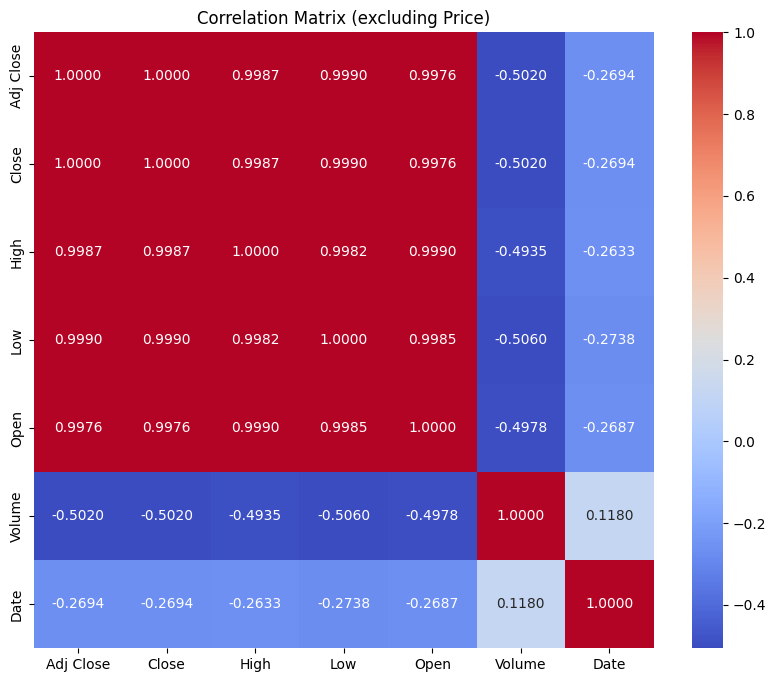

In [16]:
# Create the correlation matrix excluding the 'Price' column
correlation_matrix = df.drop('Price', axis=1).corr()

# Plot the correlation matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".4f")
plt.title('Correlation Matrix (excluding Price)')
plt.show()


This completely make sense because of the type of the data

### Data Split

Use temporal Split for spliting our data

In [17]:
from sklearn.model_selection import TimeSeriesSplit

# Define the number of splits for TimeSeriesSplit
n_splits = 5

# Create a TimeSeriesSplit object
tscv = TimeSeriesSplit(n_splits=n_splits)

# Iterate through the splits
for train_index, test_index in tscv.split(df):
    train_data = df.iloc[train_index]
    test_data = df.iloc[test_index]

    print(f"Train data shape: {train_data.shape}")
    print(f"Test data shape: {test_data.shape}")
    # Now you have train_data and test_data for each split
    # You can use them for training and evaluating your models


Train data shape: (647, 8)
Test data shape: (642, 8)
Train data shape: (1289, 8)
Test data shape: (642, 8)
Train data shape: (1931, 8)
Test data shape: (642, 8)
Train data shape: (2573, 8)
Test data shape: (642, 8)
Train data shape: (3215, 8)
Test data shape: (642, 8)


Scale the train and test data

In [18]:

from sklearn.preprocessing import MinMaxScaler

# Create a MinMaxScaler object
scaler = MinMaxScaler()

# Fit the scaler on the training data
train_data[['Adj Close']] = scaler.fit_transform(train_data[['Adj Close']])

# Transform the test data using the same scaler
test_data[['Adj Close']] = scaler.transform(test_data[['Adj Close']])

In [19]:
train_data.head()

,Price,Adj Close,Close,High,Low,Open,Volume,Date
2,2010-01-04,0.621139,81.510002,81.680000,79.629997,79.629997,263542,2010-01-04
3,2010-01-05,0.623473,81.769997,82.000000,80.949997,81.629997,258887,2010-01-05
4,2010-01-06,0.636135,83.180000,83.519997,80.849998,81.430000,370059,2010-01-06
5,2010-01-07,0.631466,82.660004,83.360001,82.260002,83.199997,246632,2010-01-07
6,2010-01-08,0.632274,82.750000,83.470001,81.800003,82.650002,310377,2010-01-08


In [20]:
test_data.head()

,Price,Adj Close,Close,High,Low,Open,Volume,Date
3219,2022-10-17,0.656609,85.459999,87.120003,84.610001,85.589996,172020,2022-10-17
3220,2022-10-18,0.632902,82.820000,86.510002,82.089996,85.699997,97304,2022-10-18
3221,2022-10-19,0.657417,85.550003,86.199997,82.589996,83.690002,71309,2022-10-19
3222,2022-10-20,0.661279,85.980003,88.169998,85.220001,85.940002,338344,2022-10-20
3223,2022-10-21,0.652927,85.050003,85.900002,83.150002,85.070000,272803,2022-10-21


Building the sequence of days with window size 30 as mentioned in the paper

Create Sequences for training with window size 30. The "Adj Close" column is the target column

In [21]:
import numpy as np

def create_sequences(data, seq_length):
    xs = []
    ys = []
    for i in range(len(data)-seq_length-1):
        x = data[i:(i+seq_length)]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# Example usage:
seq_length = 30

# Create sequences for train and test data
sequences_x, sequences_y = create_sequences(train_data['Adj Close'].values, seq_length)
test_sequences_x, test_sequences_y = create_sequences(test_data['Adj Close'].values, seq_length)

## Part 1.2

### HyperParameters

According to the paper the followings are hyperparameters

In [22]:

import tensorflow as tf

learning_rate = 0.001
batch_size = 100
epochs = 50

# For example to create an Adam optimizer with the specified learning rate:
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

# And also use tan activation function
activation = 'tanh'

### LSTM

In [23]:

# Assuming sequences_x and sequences_y are defined as in the previous code.

lstm_model = tf.keras.Sequential([
    tf.keras.layers.LSTM(512, activation=activation, input_shape=(sequences_x.shape[1], 1)),
    tf.keras.layers.Dense(1)
])

lstm_model.compile(optimizer=optimizer, loss='mse')
lstm_model.fit(sequences_x.reshape(sequences_x.shape[0], sequences_x.shape[1], 1), sequences_y, epochs=epochs, batch_size=batch_size)


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0515
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 9.4532e-04
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 6.0908e-04
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.2081e-04
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 5.2107e-04
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 6.2549e-04
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 5.8379e-04
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 5.4619e-04
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 5.6691e-04
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 5.2871e-04
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.0254e-04
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.1471e-04
Epoch 13/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 5.4470e-04
Epoch 14/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4.8966e-04
Epoch 15/50
32/32 ━

Predict the test data using LSTM model and then inverse transform it for predicting real values

In [24]:
# Predict the test data
predicted_stock_price = lstm_model.predict(test_sequences_x.reshape(test_sequences_x.shape[0], test_sequences_x.shape[1], 1))

# Inverse transform the predicted values
predicted_stock_price = scaler.inverse_transform(predicted_stock_price)

# Inverse transform the actual test values
actual_stock_price = scaler.inverse_transform(test_sequences_y.reshape(-1, 1))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


### RNN

In [25]:
rnn_model = tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(512, activation=activation, input_shape=(sequences_x.shape[1], 1)),
    tf.keras.layers.Dense(1)
])

#Define the optimizer again
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

rnn_model.compile(optimizer=optimizer, loss='mse')
rnn_model.fit(sequences_x.reshape(sequences_x.shape[0], sequences_x.shape[1], 1), sequences_y, epochs=epochs, batch_size=batch_size)


# Predict the test data
predicted_stock_price_rnn = rnn_model.predict(test_sequences_x.reshape(test_sequences_x.shape[0], test_sequences_x.shape[1], 1))

# Inverse transform the predicted values
predicted_stock_price_rnn = scaler.inverse_transform(predicted_stock_price_rnn)

# Inverse transform the actual test values
actual_stock_price = scaler.inverse_transform(test_sequences_y.reshape(-1, 1))


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - loss: 0.3086
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0860
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0044
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8455e-04
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5981e-04
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3345e-04
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3090e-04
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.6742e-04
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.0585e-04
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.8199e-04
Epoch 13/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.5940e-04
Epoch 14/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.1135e-04
Epoch 15/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/s

### Bi-LSTM

In [26]:
# Assuming sequences_x and sequences_y are defined as in the previous code.

bi_lstm_model = tf.keras.Sequential([
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(1024, activation=activation), input_shape=(sequences_x.shape[1], 1)),
    tf.keras.layers.Dense(1)
])

#Define the optimizer again
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

bi_lstm_model.compile(optimizer=optimizer, loss='mse')
bi_lstm_model.fit(sequences_x.reshape(sequences_x.shape[0], sequences_x.shape[1], 1), sequences_y, epochs=epochs, batch_size=batch_size)

# Predict the test data
predicted_stock_price_bi_lstm = bi_lstm_model.predict(test_sequences_x.reshape(test_sequences_x.shape[0], test_sequences_x.shape[1], 1))

# Inverse transform the predicted values
predicted_stock_price_bi_lstm = scaler.inverse_transform(predicted_stock_price_bi_lstm)


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0527
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0017
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0011
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 9.1079e-04
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.0010
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 6.8662e-04
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 7.6515e-04
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 6.0436e-04
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 7.5999e-04
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 5.8463e-04
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 5.5696e-04
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 5.7369e-04
Epoch 13/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 5.5797e-04
Epoch 14/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 7.1925e-04
Epoch 15/50
32/32 ━━━━━━━━━━━━━

### GRU

In [27]:
gru_model = tf.keras.Sequential([
    tf.keras.layers.GRU(512, activation=activation, input_shape=(sequences_x.shape[1], 1)),
    tf.keras.layers.Dense(1)
])

#Define the optimizer again
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

gru_model.compile(optimizer=optimizer, loss='mse')
gru_model.fit(sequences_x.reshape(sequences_x.shape[0], sequences_x.shape[1], 1), sequences_y, epochs=epochs, batch_size=batch_size)

# Predict the test data
predicted_stock_price_gru = gru_model.predict(test_sequences_x.reshape(test_sequences_x.shape[0], test_sequences_x.shape[1], 1))

# Inverse transform the predicted values
predicted_stock_price_gru = scaler.inverse_transform(predicted_stock_price_gru)


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0807
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0017
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.9544e-04
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.7543e-04
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.4328e-04
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.5943e-04
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.4301e-04
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.2671e-04
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.0082e-04
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 3.3001e-04
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.3487e-04
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.0943e-04
Epoch 13/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.2039e-04
Epoch 14/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.5658e-04
Epoch 15/50
32/32 ━━━━━

### Result Comparision

 Now use plotly and plot the real values of the test data and the predicted result for each model

In [28]:
import numpy as np
import plotly.graph_objects as go

fig = go.Figure()

# Add the actual values
fig.add_trace(go.Scatter(x=np.arange(len(actual_stock_price)), y=actual_stock_price.flatten(), mode='lines', name='Actual'))

# Add LSTM predictions
fig.add_trace(go.Scatter(x=np.arange(len(predicted_stock_price)), y=predicted_stock_price.flatten(), mode='lines', name='LSTM'))

# Add RNN predictions
fig.add_trace(go.Scatter(x=np.arange(len(predicted_stock_price_rnn)), y=predicted_stock_price_rnn.flatten(), mode='lines', name='RNN'))

# Add Bi-LSTM predictions
fig.add_trace(go.Scatter(x=np.arange(len(predicted_stock_price_bi_lstm)), y=predicted_stock_price_bi_lstm.flatten(), mode='lines', name='Bi-LSTM'))

# Add GRU predictions
fig.add_trace(go.Scatter(x=np.arange(len(predicted_stock_price_gru)), y=predicted_stock_price_gru.flatten(), mode='lines', name='GRU'))


fig.update_layout(title='Actual vs Predicted Stock Prices', xaxis_title='Time Steps', yaxis_title='Stock Price')
fig.show()


### Describing Metrics

This document describes four commonly used regression evaluation metrics: **MAE**, **MAPE**, **RMSE**, and **R² (R-Squared)**, with formulas and detailed explanations.

---

## Mean Absolute Error (MAE)

**Definition:**  
MAE measures the average magnitude of the errors in a set of predictions, without considering their direction. It is a linear score which means all individual differences are weighted equally.

**Formula:**

$$
\mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i \right|
$$

- $y_i$ = actual/true value  
- $\hat{y}_i$ = predicted value  
- $n$ = number of observations  

**Interpretation:**  
Lower MAE values indicate better model performance. Since it uses absolute differences, it doesn’t penalize large errors as much as RMSE.

---

## Mean Absolute Percentage Error (MAPE)

**Definition:**  
MAPE expresses the prediction error as a percentage of the actual values. It is useful when you want a scale-independent measure.

**Formula:**

$$
\mathrm{MAPE} = \frac{100}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right|
$$

**Note:**  
- MAPE can be **undefined** or **infinite** if any $y_i = 0$ (division by zero).
- Best used when target values are all positive and significantly different from zero.

**Interpretation:**  
A MAPE of 5% means the average absolute error is 5% of the actual values. Smaller is better.

---

## Root Mean Squared Error (RMSE)

**Definition:**  
RMSE measures the square root of the average of squared differences between prediction and actual values. It gives a higher weight to large errors.

**Formula:**

$$
\mathrm{RMSE} = \sqrt{ \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 }
$$

**Interpretation:**  
RMSE is sensitive to outliers and is generally higher than MAE. When large errors are undesirable, RMSE is more informative than MAE.

---

## Coefficient of Determination (R², R-Squared)

**Definition:**  
R² represents the proportion of the variance in the dependent variable that is predictable from the independent variables.

**Formula:**

$$
R^2 = 1 - \frac{ \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 }{ \sum_{i=1}^{n} (y_i - \bar{y})^2 }
$$

- $\bar{y} = \frac{1}{n} \sum_{i=1}^n y_i$ = mean of actual values

**Interpretation:**  
- $R^2 = 1$: Perfect prediction  
- $R^2 = 0$: Model does no better than the mean  
- $R^2 < 0$: Model performs worse than simply predicting the mean  

R² is widely used but can be misleading in non-linear models or when dealing with outliers.

---


Now we use the above metric for showing our results

In [29]:

from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score
import pandas as pd

def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    return mae, mape, rmse, r2

lstm_metrics = calculate_metrics(actual_stock_price, predicted_stock_price)
rnn_metrics = calculate_metrics(actual_stock_price, predicted_stock_price_rnn)
bi_lstm_metrics = calculate_metrics(actual_stock_price, predicted_stock_price_bi_lstm)
gru_metrics = calculate_metrics(actual_stock_price, predicted_stock_price_gru)


results_df = pd.DataFrame({
    'Metric': ['MAE', 'MAPE', 'RMSE', 'R-squared'],
    'LSTM': lstm_metrics,
    'RNN': rnn_metrics,
    'Bi-LSTM': bi_lstm_metrics,
    'GRU': gru_metrics
})

results_df


,Metric,LSTM,RNN,Bi-LSTM,GRU
0,MAE,1.605043,1.687488,1.718862,1.326177
1,MAPE,0.021325,0.022422,0.022719,0.017684
2,RMSE,1.979034,2.082586,2.090203,1.668695
3,R-squared,0.898351,0.887435,0.886610,0.927731


## Part 1.3 (Bonus)

### Description ARIMA and SARIMA

## ARIMA Model (AutoRegressive Integrated Moving Average)

**Definition:**  
ARIMA is a widely used time series forecasting model that combines three components:
- **AR (AutoRegressive)**: Regression of the variable against its own lagged values.
- **I (Integrated)**: Differencing of raw observations to make the time series stationary.
- **MA (Moving Average)**: Modeling the error term as a linear combination of past error terms.

**Notation:**
$$
\text{ARIMA}(p, d, q)
$$

- $p$: number of lag observations included in the model (AR part)  
- $d$: number of times the raw observations are differenced (I part)  
- $q$: size of the moving average window (MA part)

**Mathematical Form:**

An ARIMA$(p, d, q)$ model for a differenced series $y_t$ is:

$$
\phi(B)(1 - B)^d y_t = \theta(B)\varepsilon_t
$$

Where:  
- $B$ is the backshift operator: $B y_t = y_{t-1}$  
- $\phi(B)$ is the AR polynomial  
- $\theta(B)$ is the MA polynomial  
- $\varepsilon_t$ is white noise

---

## SARIMA Model (Seasonal ARIMA)

**Definition:**  
SARIMA extends ARIMA by explicitly modeling **seasonality** in the data using seasonal AR, I, and MA terms. It is suitable for time series with periodic seasonal patterns.

**Notation:**
$$
\text{SARIMA}(p, d, q)(P, D, Q)_s
$$

- $p, d, q$: non-seasonal ARIMA components  
- $P, D, Q$: seasonal components (AR, I, MA respectively)  
- $s$: number of time steps per season (e.g., 12 for monthly data with yearly seasonality)

**Mathematical Form:**

SARIMA includes both non-seasonal and seasonal operators:

$$
\Phi(B^s)\phi(B)(1 - B)^d(1 - B^s)^D y_t = \Theta(B^s)\theta(B)\varepsilon_t
$$

Where:  
- $\phi(B)$ and $\theta(B)$: non-seasonal AR and MA polynomials  
- $\Phi(B^s)$ and $\Theta(B^s)$: seasonal AR and MA polynomials  
- $(1 - B)^d$: non-seasonal differencing  
- $(1 - B^s)^D$: seasonal differencing

---

## Key Differences Between ARIMA and SARIMA

| Feature              | ARIMA                      | SARIMA                              |
|---------------------|----------------------------|--------------------------------------|
| Seasonality         | ❌ Not explicitly modeled   | ✅ Explicitly modeled                |
| Notation            | ARIMA(p, d, q)             | SARIMA(p, d, q)(P, D, Q)<sub>s</sub> |
| Best for            | Stationary, non-seasonal   | Seasonal time series                 |
| Complexity          | Simpler                    | More complex due to seasonal terms   |
| Use case example    | Stock prices               | Monthly temperature, quarterly sales |

---


### ARIMA Model: Parameters and Mathematical Concept

## What is ARIMA?

**ARIMA (AutoRegressive Integrated Moving Average)** is a statistical model used for analyzing and forecasting univariate time series data. It combines **autoregression (AR)**, **differencing (I)** for stationarity, and **moving average (MA)** components.

---

## ARIMA(p, d, q) Parameters Explained

| Parameter | Name             | Description                                                                 |
|-----------|------------------|-----------------------------------------------------------------------------|
| $p$       | AutoRegressive   | Number of lag observations included in the model (how many past values to use) |
| $d$       | Integrated       | Number of times the data are differenced to make the series stationary       |
| $q$       | Moving Average   | Number of lagged forecast errors used in the prediction equation              |

---

## ARIMA Mathematical Formulation

The general form of an ARIMA model is:

$$
\phi(B)(1 - B)^d y_t = \theta(B) \varepsilon_t
$$

Where:

- $y_t$: the actual time series value at time $t$
- $B$: backshift (lag) operator, i.e., $B y_t = y_{t-1}$
- $\varepsilon_t$: white noise (random error term)
- $\phi(B)$: AR polynomial, $\phi(B) = 1 - \phi_1 B - \phi_2 B^2 - \dots - \phi_p B^p$
- $\theta(B)$: MA polynomial, $\theta(B) = 1 + \theta_1 B + \theta_2 B^2 + \dots + \theta_q B^q$
- $(1 - B)^d$: differencing operator applied $d$ times to achieve stationarity

---

## Breakdown of Components

### 1. **AutoRegressive (AR) part - $p$**

- This part uses the **past values** of the series to predict the future.
- The AR($p$) process is defined as:
  $$
  y_t = c + \sum_{i=1}^{p} \phi_i y_{t-i} + \varepsilon_t
  $$
- $\phi_i$ are coefficients for the lag terms $y_{t-i}$.

---

### 2. **Integrated (I) part - $d$**

- Differencing removes trends and makes the series **stationary**.
- First difference: $(1 - B)y_t = y_t - y_{t-1}$
- Repeated $d$ times to remove trend or seasonality:
  $$
  y'_t = (1 - B)^d y_t
  $$

---

### 3. **Moving Average (MA) part - $q$**

- This part uses **past forecast errors** to model the current value.
- The MA($q$) process is:
  $$
  y_t = c + \varepsilon_t + \sum_{j=1}^{q} \theta_j \varepsilon_{t-j}
  $$
- $\theta_j$ are weights on past error terms $\varepsilon_{t-j}$.

---

## When to Use ARIMA

- Data must be **univariate** (one variable over time).
- Suitable when the series shows **trends but no clear seasonal patterns**.
- Requires **stationarity** (which is addressed by the $d$ parameter).

---

## Intuition

ARIMA models the data as a **combination of memory (AR), trend adjustment (I), and error correction (MA)**. It’s like saying:

> "Today’s value = a weighted combination of past values + a correction for past mistakes + adjustment for trend."

---


**Important**

As Arima model can forecast one time step based on a window size. We should design it in a way that it would be able to predict a singel cost in 1 step. and them use the previous results in [window size] for predicting. **Otherwise the ARIMA model would always predict a straight line**

In the following cell I use Arima model for predicting each test sample at an iteration and then as we know what happened, we can add that to training data and itteratively predict the result. As in the paper the result they got is better than all the models. They should have probably used ARIMA model like the cell bellow

In [30]:
# prompt: Train an ARIMA model on the data and Predict the test data for comparision. Use good values for p, d, q (window size 30 is appropriate)

import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error, r2_score
# import tqdm
from tqdm import tqdm

# Assuming train_data and test_data are defined as in the previous code
# and contain the 'Adj Close' column with scaled values. extract

train_data_arima = train_data["Adj Close"].values.flatten().tolist()
test_data_arima = test_data["Adj Close"].values.flatten().tolist()

# Limit this just for first 100 test data
test_data_arima = test_data_arima[:100]

# No we use tqdm and in each step we forecast one step and then add that to train_data
arima_predictions = list()

#Start for loop
for t in tqdm(range(len(test_data_arima))):
    model = ARIMA(train_data_arima, order=(2,0,2))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    obs = test_data_arima[t]

    # Add to prediction list
    arima_predictions.append(yhat)

    print(obs, yhat)
    train_data_arima = np.append(train_data_arima, obs)

  1%|          | 1/100 [00:01<02:11,  1.33s/it]

0.6566092047044507 0.6579941545592101


  2%|▏         | 2/100 [00:02<02:04,  1.27s/it]

0.6329023129514558 0.6570710234188151


  3%|▎         | 3/100 [00:07<04:38,  2.88s/it]

...

0.577586255031497 0.5861342396032514


 99%|█████████▉| 99/100 [02:42<00:02,  2.19s/it]

0.5691451409110364 0.5781072467437877


/usr/local/lib/python3.11/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

100%|██████████| 100/100 [02:45<00:00,  1.66s/it]

0.5777658225929356 0.5691960113800714


In [31]:

arima_metrics = calculate_metrics(test_data_arima, arima_predictions)

results_df['ARIMA'] = arima_metrics

results_df


,Metric,LSTM,RNN,Bi-LSTM,GRU,ARIMA
0,MAE,1.605043,1.687488,1.718862,1.326177,0.012811
1,MAPE,0.021325,0.022422,0.022719,0.017684,0.021181
2,RMSE,1.979034,2.082586,2.090203,1.668695,0.015501
3,R-squared,0.898351,0.887435,0.886610,0.927731,0.870292


The only thing we can check is R2 score because I didn't rescale them for faster inference and as you see the R2 Score of ARIMA is better than other models the same as the paper

# Code Comparison and Analysis

This document analyzes the provided Python code, focusing on its functionality, structure, and potential improvements.

## Code Overview

The code performs time series analysis and forecasting on oil price data.  Key steps include:

1. **Data Loading and Preparation:** Loads data from a CSV file, handles missing values and negative entries, and converts the 'Date' column to datetime objects. Identifies and reports missing dates.

2. **Visualization:** Generates a histogram of price distribution and line plots of Open, High, Low, and Close prices over time. Also displays a correlation matrix.

3. **Data Splitting and Scaling:** Employs `TimeSeriesSplit` for temporal data splitting and `MinMaxScaler` for feature scaling.

4. **Model Training:** Trains several deep learning models: LSTM, RNN, Bi-LSTM, and GRU. Uses an Adam optimizer and tanh activation.  The hyperparameters and architecture are set based on a referenced paper (the specific paper is not provided in the code).

5. **Model Evaluation:** Predicts on test data, performs inverse transformations to obtain actual stock prices, and creates a plot comparing actual vs. predicted prices for each model.


6. **Metric Calculation:** Calculates Mean Absolute Error (MAE), Mean Absolute Percentage Error (MAPE), Root Mean Squared Error (RMSE), and R-squared for each model.  Presents these metrics in a table.


7. **ARIMA Model (Bonus):** Implements an iterative ARIMA model for forecasting, where predictions are added to the training data for subsequent predictions.

## Potential Improvements and Recommendations

1. **Data Handling:**
    * **Missing Dates:**  The code correctly identifies missing dates, but does not address the issue properly. Interpolation should not be used in time-series data, but a more sophisticated approach like using a model specifically designed for missing data might be considered.

2. **Model Evaluation:**
    * **Metrics Interpretation:** While calculating multiple metrics is good, the code lacks in-depth analysis of the results. The code should not just show the numbers, but clearly state which model performed better based on each metric, overall model performance, and provide explanation for performance difference among models.

3. **ARIMA Model:**
    * **Model Parameter Tuning**: The ARIMA model uses fixed parameters (`order=(5, 1, 2)`).  These parameters should be optimized using techniques like grid search or auto ARIMA.

4. **Code Structure:**
   * **Modularization**: Break down the code into well-defined functions, such as `load_data()`, `visualize_data()`, `train_model()`, and `evaluate_model()`. This enhances readability, reusability, and maintainability.

5. **Documentation:**
   * **Comments and Docstrings**: Provide comprehensive comments within the code and use docstrings to clearly document functions and classes, including parameters, return values, and purpose.


## Comparison of Models

The code provides a comparative visualization of the LSTM, RNN, Bi-LSTM, GRU, and ARIMA model predictions against the actual values.  The table of calculated metrics helps quantify the performance of these models.  However, additional analysis of these results is needed to clearly draw conclusion on models' performance.


## Conclusion

The provided code is a functional starting point for time series forecasting. However, it can be significantly improved through careful consideration of missing data, thorough metric interpretation, parameter tuning for the ARIMA model, enhanced code structure, and detailed documentation. The addition of more sophisticated analyses, as well as better data handling would significantly improve the insights derived from this code.